In [59]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score,roc_auc_score,classification_report,confusion_matrix)
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier

In [61]:
# Load the dataset from the repository's data/ folder
from pathlib import Path

DATA_PATH = Path("../data/UCI_Credit_Card.csv")

if not DATA_PATH.exists():
    raise FileNotFoundError(
        "Dataset not found. Download UCI_Credit_Card.csv and place it in the "
        "'data/' folder at the repository root."
    )

df = pd.read_csv(DATA_PATH)

In [62]:
#Checking Distribution of Target Values
target = 'default.payment.next.month'
counts = df[target].value_counts().sort_index()
print(counts)

default.payment.next.month
0    23364
1     6636
Name: count, dtype: int64


In [63]:
#Checking Distribution of Clients as percentage
percentages = df[target].value_counts(normalize=True) * 100
print(percentages.sort_index())

default.payment.next.month
0    77.88
1    22.12
Name: proportion, dtype: float64


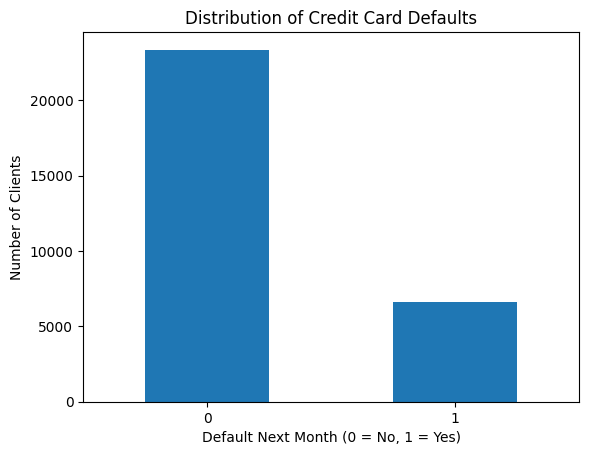

In [64]:
#Ploting Distribution of Clients
counts.plot(kind='bar')

plt.title('Distribution of Credit Card Defaults')
plt.xlabel('Default Next Month (0 = No, 1 = Yes)')
plt.ylabel('Number of Clients')
plt.xticks(rotation=0)

plt.show()

In [65]:
#Analyzing Age
df['AGE'].describe()

,AGE
count,30000.000000
mean,35.485500
std,9.217904
min,21.000000
25%,28.000000
50%,34.000000
75%,41.000000
max,79.000000


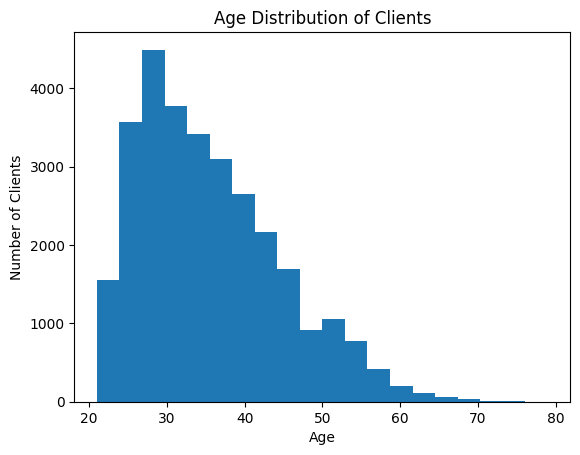

In [66]:
#Plotting Distribution of Clients by Age
df['AGE'].plot(kind='hist',bins=20)

plt.title('Age Distribution of Clients')
plt.xlabel("Age")
plt.ylabel('Number of Clients')

plt.show()

In [67]:
#Analyzing Credit Limits
df['LIMIT_BAL'].describe()

,LIMIT_BAL
count,30000.000000
mean,167484.322667
std,129747.661567
min,10000.000000
25%,50000.000000
50%,140000.000000
75%,240000.000000
max,1000000.000000


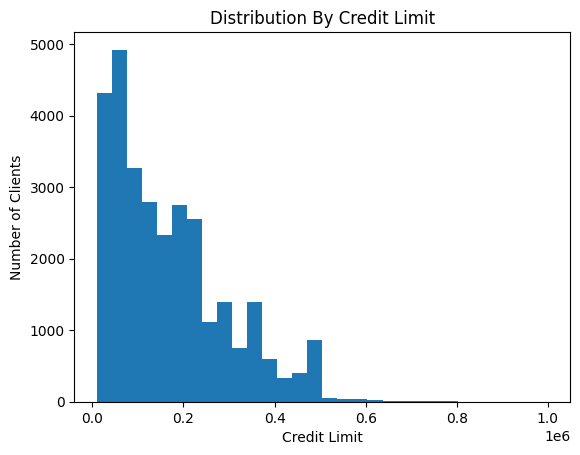

In [68]:
#Plot of Client Distribution by Credit Limit

df['LIMIT_BAL'].plot(kind='hist',bins=30)

plt.title("Distribution By Credit Limit")
plt.xlabel('Credit Limit')
plt.ylabel('Number of Clients')

plt.show()

In [69]:
#Creating Age Groups for Analysis

age_bins = [20,30,40,50,60,80]

age_labels = ['20-29','30-39','40-49','50-59','60-79']

df['AGE_GROUP'] = pd.cut(
    df['AGE'],
    bins=age_bins,
    labels=age_labels,
    right=False
)

In [70]:
#Finding Default Rates of Each Age Group
default_rates = df.groupby('AGE_GROUP')['default.payment.next.month'].mean() * 100

print(default_rates)

AGE_GROUP
20-29    22.842587
30-39    20.252714
40-49    22.973391
50-59    24.861170
60-79    28.318584
Name: default.payment.next.month, dtype: float64


/tmp/ipykernel_545/64442223.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  default_rates = df.groupby('AGE_GROUP')['default.payment.next.month'].mean() * 100


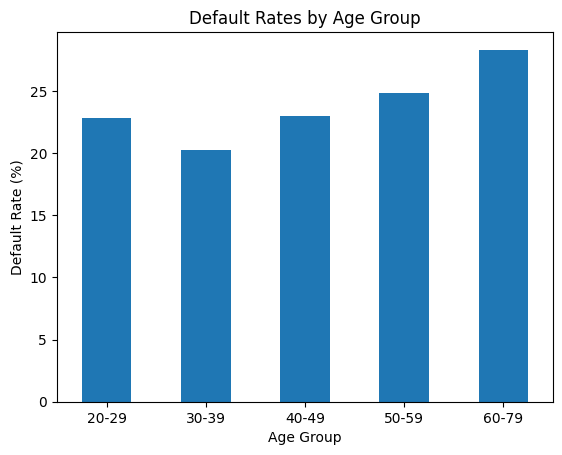

In [71]:
#Plotting Default Rates of Each Age Group
default_rates.plot(kind='bar')

plt.title("Default Rates by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Default Rate (%)")
plt.xticks(rotation=0)

plt.show()

In [72]:
#Calculating Age Range and Default rates together

age_analysis = df.groupby('AGE_GROUP', observed=True)['default.payment.next.month'].agg(['count','sum','mean'])

age_analysis['default_rate'] = age_analysis['mean'] * 100

print(age_analysis)

           count   sum      mean  default_rate
AGE_GROUP                                     
20-29       9618  2197  0.228426     22.842587
30-39      11238  2276  0.202527     20.252714
40-49       6464  1485  0.229734     22.973391
50-59       2341   582  0.248612     24.861170
60-79        339    96  0.283186     28.318584


In [73]:
df['LIMIT_GROUP'] = pd.qcut(df['LIMIT_BAL'], q=5)

In [74]:
#Calculating Limit range and Default Rates together
limit_analysis = df.groupby('LIMIT_GROUP', observed=True)['default.payment.next.month'].mean() * 100

print(limit_analysis)

LIMIT_GROUP
(9999.999, 50000.0]      31.787389
(50000.0, 100000.0]      25.798424
(100000.0, 180000.0]     19.859546
(180000.0, 270000.0]     16.860358
(270000.0, 1000000.0]    13.796576
Name: default.payment.next.month, dtype: float64


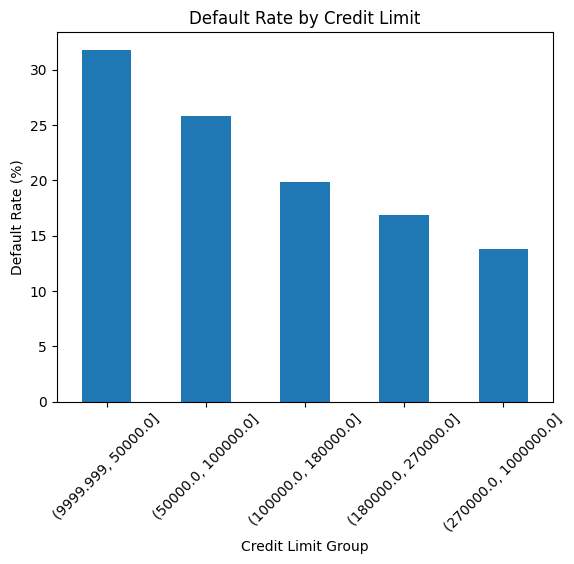

In [75]:
#Plotting Default Rates of Each Limit Range

limit_analysis.plot(kind='bar')

plt.title('Default Rate by Credit Limit')
plt.xlabel('Credit Limit Group')
plt.ylabel("Default Rate (%)")
plt.xticks(rotation=45)

plt.show()

In [76]:
limit_analysis = df.groupby('LIMIT_GROUP', observed=True)['default.payment.next.month'].agg(['count','sum','mean'])

limit_analysis['defaul_rate'] = limit_analysis['mean'] * 100

print(limit_analysis)

                       count   sum      mean  defaul_rate
LIMIT_GROUP                                              
(9999.999, 50000.0]     7676  2440  0.317874    31.787389
(50000.0, 100000.0]     4822  1244  0.257984    25.798424
(100000.0, 180000.0]    6123  1216  0.198595    19.859546
(180000.0, 270000.0]    5421   914  0.168604    16.860358
(270000.0, 1000000.0]   5958   822  0.137966    13.796576


In [77]:
#Investigating Repayment History

print(df['PAY_0'].value_counts().sort_index())

PAY_0
-2     2759
-1     5686
 0    14737
 1     3688
 2     2667
 3      322
 4       76
 5       26
 6       11
 7        9
 8       19
Name: count, dtype: int64


In [78]:
#Calculating Default Rate of Each Category

pay_analysis = df.groupby('PAY_0')['default.payment.next.month'].agg(['count','sum','mean'])

pay_analysis['default_rate'] = pay_analysis['mean'] * 100

print(pay_analysis)

       count   sum      mean  default_rate
PAY_0                                     
-2      2759   365  0.132294     13.229431
-1      5686   954  0.167781     16.778051
 0     14737  1888  0.128113     12.811291
 1      3688  1252  0.339479     33.947939
 2      2667  1844  0.691414     69.141357
 3       322   244  0.757764     75.776398
 4        76    52  0.684211     68.421053
 5        26    13  0.500000     50.000000
 6        11     6  0.545455     54.545455
 7         9     7  0.777778     77.777778
 8        19    11  0.578947     57.894737


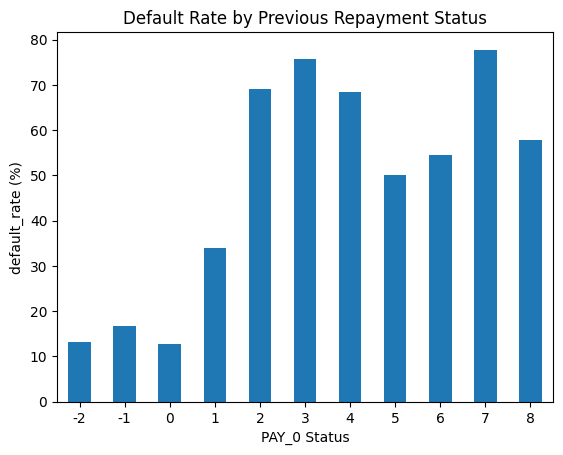

In [79]:
#Plot of Payment Analysis

pay_analysis['default_rate'].plot(kind='bar')

plt.title('Default Rate by Previous Repayment Status')
plt.xlabel('PAY_0 Status')
plt.ylabel('default_rate (%)')
plt.xticks(rotation=0)

plt.show()

In [80]:
pay_columns = [
    'PAY_0', 'PAY_2', 'PAY_3',
    'PAY_4', 'PAY_5', 'PAY_6'
]

for column in pay_columns:
    default_rate = df.groupby(column)['default.payment.next.month'].mean() * 100

    print('\n', column)
    print(default_rate)


 PAY_0
PAY_0
-2    13.229431
-1    16.778051
 0    12.811291
 1    33.947939
 2    69.141357
 3    75.776398
 4    68.421053
 5    50.000000
 6    54.545455
 7    77.777778
 8    57.894737
Name: default.payment.next.month, dtype: float64

 PAY_2
PAY_2
-2    18.270756
-1    15.966942
 0    15.912270
 1    17.857143
 2    55.614973
 3    61.656442
 4    50.505051
 5    60.000000
 6    75.000000
 7    60.000000
 8     0.000000
Name: default.payment.next.month, dtype: float64

 PAY_3
PAY_3
-2    18.531212
-1    15.594476
 0    17.451155
 1    25.000000
 2    51.557999
 3    57.500000
 4    57.894737
 5    57.142857
 6    60.869565
 7    81.481481
 8    66.666667
Name: default.payment.next.month, dtype: float64

 PAY_4
PAY_4
-2    19.250230
-1    15.895903
 0    18.328775
 1    50.000000
 2    52.326686
 3    61.111111
 4    66.666667
 5    51.428571
 6    40.000000
 7    82.758621
 8    50.000000
Name: default.payment.next.month, dtype: float64

 PAY_5
PAY_5
-2     19.687637
-1     16.194

In [81]:
#Plotting Repayment Rates of all 6 Months

repayment_rates = {}

for column in pay_columns:
    rates = df.groupby(column)['default.payment.next.month'].mean() * 100

    repayment_rates[column] = rates

repayment_table = pd.DataFrame(repayment_rates)

print(repayment_table)

        PAY_0      PAY_2      PAY_3      PAY_4       PAY_5       PAY_6
-2  13.229431  18.270756  18.531212  19.250230   19.687637   20.040858
-1  16.778051  15.966942  15.594476  15.895903   16.194259   16.986063
 0  12.811291  15.912270  17.451155  18.328775   18.852894   18.844406
 1  33.947939  17.857143  25.000000  50.000000         NaN         NaN
 2  69.141357  55.614973  51.557999  52.326686   54.188880   50.650759
 3  75.776398  61.656442  57.500000  61.111111   63.483146   64.130435
 4  68.421053  50.505051  57.894737  66.666667   60.714286   63.265306
 5  50.000000  60.000000  57.142857  51.428571   58.823529   53.846154
 6  54.545455  75.000000  60.869565  40.000000   75.000000   73.684211
 7  77.777778  60.000000  81.481481  82.758621   82.758621   82.608696
 8  57.894737   0.000000  66.666667  50.000000  100.000000  100.000000


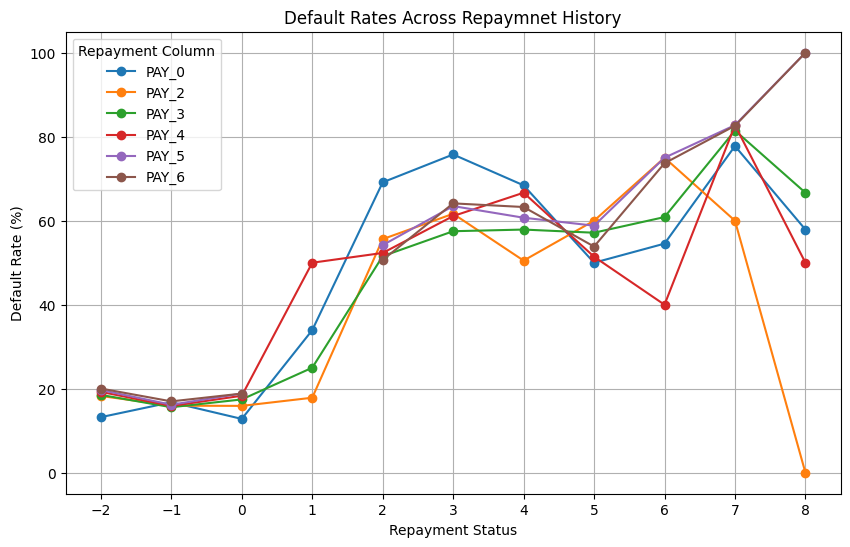

In [82]:
repayment_table = repayment_table.reindex(range(-2,9))

repayment_table.plot(kind = 'line', marker = 'o', figsize=(10,6))

plt.title('Default Rates Across Repaymnet History')
plt.xlabel('Repayment Status')
plt.ylabel('Default Rate (%)')
plt.xticks(range(-2,9))
plt.legend(title='Repayment Column')
plt.grid(True)

plt.show()

In [83]:
#Investigating Default Rates in Relation to Number of Clients Per Month

for column in pay_columns:
    print('\n', column)

    analysis = df.groupby(column)['default.payment.next.month'].agg(['count','sum','mean'])

    analysis['default_rate'] = analysis['mean'] * 100

    print(analysis)


 PAY_0
       count   sum      mean  default_rate
PAY_0                                     
-2      2759   365  0.132294     13.229431
-1      5686   954  0.167781     16.778051
 0     14737  1888  0.128113     12.811291
 1      3688  1252  0.339479     33.947939
 2      2667  1844  0.691414     69.141357
 3       322   244  0.757764     75.776398
 4        76    52  0.684211     68.421053
 5        26    13  0.500000     50.000000
 6        11     6  0.545455     54.545455
 7         9     7  0.777778     77.777778
 8        19    11  0.578947     57.894737

 PAY_2
       count   sum      mean  default_rate
PAY_2                                     
-2      3782   691  0.182708     18.270756
-1      6050   966  0.159669     15.966942
 0     15730  2503  0.159123     15.912270
 1        28     5  0.178571     17.857143
 2      3927  2184  0.556150     55.614973
 3       326   201  0.616564     61.656442
 4        99    50  0.505051     50.505051
 5        25    15  0.600000     60.00

In [84]:
#Calculating Correlation

numeric_columns = ['AGE', 'LIMIT_BAL', 'BILL_AMT1', 'PAY_AMT1']

correlation = df[numeric_columns].corr()

print(correlation )

                AGE  LIMIT_BAL  BILL_AMT1  PAY_AMT1
AGE        1.000000   0.144713   0.056239  0.026147
LIMIT_BAL  0.144713   1.000000   0.285430  0.195236
BILL_AMT1  0.056239   0.285430   1.000000  0.140277
PAY_AMT1   0.026147   0.195236   0.140277  1.000000


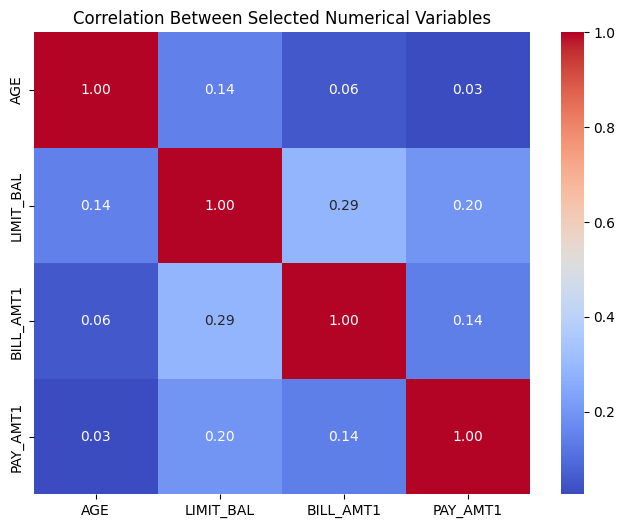

In [85]:
#Heatmap

plt.figure(figsize=(8,6))

sns.heatmap(correlation,annot=True,cmap='coolwarm',fmt='.2f')

plt.title("Correlation Between Selected Numerical Variables")

plt.show()

In [86]:
#Correlation of Values to Output
numeric_columns = ['AGE', 'LIMIT_BAL', 'BILL_AMT1','PAY_AMT1','default.payment.next.month']

correlation = df[numeric_columns].corr()

print(correlation['default.payment.next.month'].sort_values())

LIMIT_BAL                    -0.153520
PAY_AMT1                     -0.072929
BILL_AMT1                    -0.019644
AGE                           0.013890
default.payment.next.month    1.000000
Name: default.payment.next.month, dtype: float64


<function matplotlib.pyplot.show(close=None, block=None)>

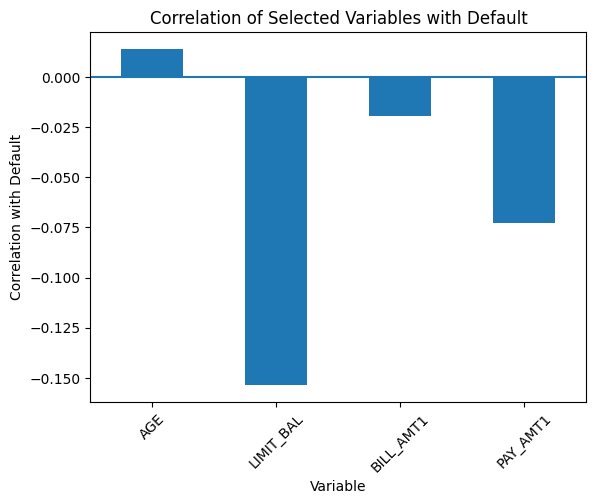

In [87]:
target_corr = correlation['default.payment.next.month'].drop('default.payment.next.month')

target_corr.plot(kind='bar')

plt.title("Correlation of Selected Variables with Default")
plt.xlabel("Variable")
plt.ylabel("Correlation with Default")
plt.xticks(rotation=45)

plt.axhline(0)

plt.show

In [88]:
education_table = pd.crosstab(df['EDUCATION'],df['default.payment.next.month'])

print(education_table)

default.payment.next.month      0     1
EDUCATION                              
0                              14     0
1                            8549  2036
2                           10700  3330
3                            3680  1237
4                             116     7
5                             262    18
6                              43     8


In [89]:
education_percentages = pd.crosstab(df['EDUCATION'],df['default.payment.next.month'],normalize = 'index') * 100

print(education_percentages)

default.payment.next.month           0          1
EDUCATION                                        
0                           100.000000   0.000000
1                            80.765234  19.234766
2                            76.265146  23.734854
3                            74.842384  25.157616
4                            94.308943   5.691057
5                            93.571429   6.428571
6                            84.313725  15.686275


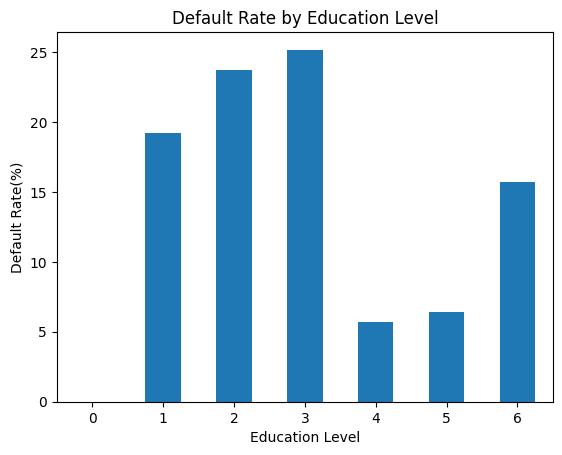

In [90]:
education_percentages[1].plot(kind='bar')

plt.title("Default Rate by Education Level")
plt.xlabel("Education Level")
plt.ylabel('Default Rate(%)')
plt.xticks(rotation=0)

plt.show()

In [91]:
chi2,p_value,dof,expected = chi2_contingency(education_table)

print('Chi-square statistic:', chi2)
print('P-value:',p_value)
print('Degrees of Freedom:',dof)

Chi-square statistic: 163.21655786997073
P-value: 1.2332626245415605e-32
Degrees of Freedom: 6


In [92]:
n = education_table.to_numpy().sum()

minimum_dimension = min(education_table.shape)

cramers_v = np.sqrt(chi2 / (n * (minimum_dimension - 1)))

print('Cramers V:', cramers_v)

Cramers V: 0.07376009713252163


In [93]:
print('Minimum expected count:', expected.min())
print('Expected cells below 5:', (expected < 5).sum())
print('Total number of cells:', expected.size)

Minimum expected count: 3.0968
Expected cells below 5: 1
Total number of cells: 14


In [94]:
age_education_table = pd.crosstab(
    df["AGE_GROUP"],
    df["EDUCATION"]
)

print(age_education_table)


EDUCATION  0     1     2     3   4    5   6
AGE_GROUP                                  
20-29      1  3698  4831   949  49   83   7
30-39      7  4457  5277  1342  42  106   7
40-49      5  1786  2961  1596  26   65  25
50-59      1   552   858   890   6   24  10
60-79      0    92   103   140   0    2   2


In [95]:
age_education_default = df.pivot_table(index='AGE_GROUP',columns='EDUCATION',values='default.payment.next.month',aggfunc='mean') * 100

print(age_education_default.round(2))

EDUCATION    0      1      2      3      4      5      6
AGE_GROUP                                               
20-29      0.0  18.88  25.44  27.50   8.16   4.82  14.29
30-39      0.0  18.56  21.57  22.73   2.38   4.72   0.00
40-49      0.0  20.32  23.84  25.19   3.85  12.31  20.00
50-59      0.0  22.28  25.76  26.29  16.67   4.17  20.00
60-79      NaN  27.17  34.95  25.00    NaN   0.00   0.00


/tmp/ipykernel_545/2282253440.py:1: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  age_education_default = df.pivot_table(index='AGE_GROUP',columns='EDUCATION',values='default.payment.next.month',aggfunc='mean') * 100


In [96]:
df_model = df.drop(columns=['ID'])

df_model = df_model.drop_duplicates()

X = df_model.drop(columns=['default.payment.next.month'])
y = df_model['default.payment.next.month']

print('Original dataset:', df.shape)
print('Dataset after cleaning:', df_model.shape)
print('Number of duplicate rows remaining:', df_model.duplicated().sum())
print('Features:', X.shape)
print('Target:', y.shape)

Original dataset: (30000, 27)
Dataset after cleaning: (29965, 26)
Number of duplicate rows remaining: 0
Features: (29965, 25)
Target: (29965,)


In [97]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

print('Training features:', X_train.shape)
print("Testing features:", X_test.shape)
print('Training target:', y_train.shape)
print('Testing target:', y_test.shape)

print('Default rate in training data:',y_train.mean() * 100)


print('Default rate in testing data:',y_test.mean() * 100)


Training features: (23972, 25)
Testing features: (5993, 25)
Training target: (23972,)
Testing target: (5993,)
Default rate in training data: 22.125813449023862
Default rate in testing data: 22.125813449023862


In [98]:
X = X.drop(columns=['AGE_GROUP','LIMIT_GROUP'], errors='ignore')

print("Number of features:", X.shape[1])
print(X.columns.tolist())

Number of features: 23
['LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6']


In [99]:
numeric_features = ['LIMIT_BAL','AGE','BILL_AMT1','BILL_AMT2','BILL_AMT3','BILL_AMT4','BILL_AMT5','BILL_AMT6','PAY_AMT1','PAY_AMT2','PAY_AMT3','PAY_AMT4','PAY_AMT5','PAY_AMT6']

categorical_features = ['SEX', 'EDUCATION','MARRIAGE','PAY_0','PAY_2','PAY_3','PAY_4','PAY_5','PAY_6']

preprocessor = ColumnTransformer(transformers = [('num',StandardScaler(),numeric_features),('cat',OneHotEncoder(handle_unknown='ignore'),categorical_features)])

print('preprocessing setup complete')

preprocessing setup complete


In [100]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size = 0.2,random_state=42,stratify=y)

print(X_train.shape)
print(X_test.shape)

(23972, 23)
(5993, 23)


In [101]:
#Building Logistic Regression Model

logistic_model = Pipeline(steps=[('preprocessing',preprocessor),('classifier',LogisticRegression(max_iter=1000))])

logistic_model.fit(X_train,y_train)

y_pred = logistic_model.predict(X_test)

y_prob = logistic_model.predict_proba(X_test)[:,1]

In [102]:
print('Accuracy:', accuracy_score(y_test,y_pred))
print("Precision:", precision_score(y_test,y_pred))
print('Recall:', recall_score(y_test,y_pred))
print("F1 Score:", f1_score(y_test,y_pred))
print('ROC-AUC:', roc_auc_score(y_test,y_prob))

print(confusion_matrix(y_test,y_pred))
print(classification_report(y_test,y_pred))

Accuracy: 0.8209577840814284
Precision: 0.6846715328467153
Recall: 0.3536953242835596
F1 Score: 0.46643460964694183
ROC-AUC: 0.7614271895898839
[[4451  216]
 [ 857  469]]
              precision    recall  f1-score   support

           0       0.84      0.95      0.89      4667
           1       0.68      0.35      0.47      1326

    accuracy                           0.82      5993
   macro avg       0.76      0.65      0.68      5993
weighted avg       0.80      0.82      0.80      5993



In [103]:
baseline = DummyClassifier(strategy='most_frequent')

baseline.fit(X_train,y_train)

baseline_pred = baseline.predict(X_test)
baseline_prob = baseline.predict_proba(X_test)[:,1]

print('Baseline Accuracy:', accuracy_score(y_test, baseline_pred))
print('Baseline Precisoin:', precision_score(y_test, baseline_pred))
print('Baseline Recall:', recall_score(y_test, baseline_pred))
print('Baseline F1:', f1_score(y_test, baseline_pred))
print('Baseline ROC-AUC:', roc_auc_score(y_test, baseline_prob))

Baseline Accuracy: 0.7787418655097614
Baseline Precisoin: 0.0
Baseline Recall: 0.0
Baseline F1: 0.0
Baseline ROC-AUC: 0.5


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [104]:
random_forest = Pipeline(steps=[('preprocessing',preprocessor),('classifier',RandomForestClassifier(n_estimators=200,max_depth=12,min_samples_split=10,random_state=42,n_jobs=-1))])

random_forest.fit(X_train,y_train)

rf_pred = random_forest.predict(X_test)
rf_prob = random_forest.predict_proba(X_test)[:,1]


In [105]:
print("Accuracy:", accuracy_score(y_test,rf_pred))
print('Precision:', precision_score(y_test,rf_pred))
print("Recall:", recall_score(y_test,rf_pred))
print("F1:", f1_score(y_test,rf_pred))
print("ROC-AUC", roc_auc_score(y_test,rf_prob))

print(confusion_matrix(y_test,rf_pred))

Accuracy: 0.8177874186550976
Precision: 0.6720588235294118
Recall: 0.34464555052790347
F1: 0.4556331006979063
ROC-AUC 0.7706791951835373
[[4444  223]
 [ 869  457]]


In [106]:
probabilities = logistic_model.predict_proba(X_test)[:,1]

thresholds = [0.3,0.4,0.5,0.6]

results = []

for threshold in thresholds:
  predictions = (probabilities >= threshold).astype(int)

  tn, fp, fn, tp = confusion_matrix(y_test,predictions).ravel()

  results.append({'Threshold':threshold, "Accuracy":accuracy_score(y_test,predictions),"Precision":precision_score(y_test,predictions),"Recall":recall_score(y_test,predictions),'F1': f1_score(y_test,predictions),'False Positives': fp,'False Negatives':fn})

results_df = pd.DataFrame(results)

print(results_df.round(4))

   Threshold  Accuracy  Precision  Recall      F1  False Positives  \
0        0.3    0.8041     0.5691  0.4721  0.5161              474   
1        0.4    0.8185     0.6455  0.3982  0.4925              290   
2        0.5    0.8210     0.6847  0.3537  0.4664              216   
3        0.6    0.8173     0.7112  0.2934  0.4154              158   

   False Negatives  
0              700  
1              798  
2              857  
3              937  


In [107]:
threshold = 0.3
predictions = (probabilities >= threshold).astype(int)

fairness_df = X_test[['SEX','AGE']]
fairness_df['Actual'] = y_test
fairness_df['Predicted'] = predictions

def group_metrics(group):
  tn,fp,fn,tp = confusion_matrix(group['Actual'],group['Predicted'],labels=[0,1]).ravel()

  return pd.Series({'Customers':len(group),'Actual Default Rate':group['Actual'].mean(),'Precision':tp/(tp+fp) if (tp+fp) else 0, 'Recall':tp/(tp+fn) if (tp+fn) else 0 , 'False Positive Rate': fp/(fp+tn) if (fp+tn) else 0})

sex_results = fairness_df.groupby("SEX").apply(group_metrics,include_groups=False)

print(sex_results.round(4))

     Customers  Actual Default Rate  Precision  Recall  False Positive Rate
SEX                                                                        
1       2332.0               0.2440     0.5553  0.4763               0.1231
2       3661.0               0.2068     0.5801  0.4690               0.0885


/tmp/ipykernel_545/3748285342.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fairness_df['Actual'] = y_test
/tmp/ipykernel_545/3748285342.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fairness_df['Predicted'] = predictions


In [108]:
fairness_df['AGE_GROUP'] = pd.cut(fairness_df['AGE'],bins=[20,30,40,50,60,80],labels=['20-29','30-39','40-49','50-59','60-79'],right=False)

age_results = fairness_df.groupby("AGE_GROUP",observed=False).apply(group_metrics,include_groups=False)

print(age_results.round(4))

           Customers  Actual Default Rate  Precision  Recall  \
AGE_GROUP                                                      
20-29         1927.0               0.2169     0.5306  0.4976   
30-39         2208.0               0.2083     0.5593  0.4304   
40-49         1298.0               0.2334     0.6059  0.4719   
50-59          493.0               0.2495     0.6535  0.5366   
60-79           67.0               0.3284     0.6471  0.5000   

           False Positive Rate  
AGE_GROUP                       
20-29                   0.1219  
30-39                   0.0892  
40-49                   0.0935  
50-59                   0.0946  
60-79                   0.1333  


/tmp/ipykernel_545/1960276457.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fairness_df['AGE_GROUP'] = pd.cut(fairness_df['AGE'],bins=[20,30,40,50,60,80],labels=['20-29','30-39','40-49','50-59','60-79'],right=False)


In [109]:
customers = df.sample(2,random_state=42)
customer_a = customers.iloc[0]
customer_b = customers.iloc[1]

numeric_columns = ['AGE','LIMIT_BAL']
categorical_columns = ['SEX','EDUCATION','MARRIAGE','PAY_0']

distances = {}

for column in numeric_columns:
  value_a = customer_a[column]
  value_b = customer_b[column]

  column_range = df[column].max() - df[column].min()

  distance = abs(value_a - value_b) / column_range

  distances[column] = distance

for column in categorical_columns:
  value_a = customer_a[column]
  value_b = customer_b[column]

  distance = 0 if value_a == value_b else 1

  distances[column] = distance

gower_distance = sum(distances.values()) / len(distances)

print("CUSTOMER A")
print(customers.iloc[0][numeric_columns + categorical_columns])

print('CUSTOMER B')
print(customers.iloc[1][numeric_columns + categorical_columns])

print('ATTRIBUTE DISTANCES')
for attribute, distance in distances.items():
  print(attribute,':',round(distance,4))

print('GOWER DISTANCE:',round(gower_distance,4))

CUSTOMER A
AGE               25
LIMIT_BAL    30000.0
SEX                1
EDUCATION          2
MARRIAGE           2
PAY_0              0
Name: 2308, dtype: object
CUSTOMER B
AGE                26
LIMIT_BAL    150000.0
SEX                 2
EDUCATION           1
MARRIAGE            2
PAY_0               0
Name: 22404, dtype: object
ATTRIBUTE DISTANCES
AGE : 0.0172
LIMIT_BAL : 0.1212
SEX : 1
EDUCATION : 1
MARRIAGE : 0
PAY_0 : 0
GOWER DISTANCE: 0.3564


In [110]:
'''
TOOLS USED
- AI tools were used to aid in debugging code, interpreting results, explaining concepts, checking methodologies used and development of final write-up
'''

'\nTOOLS USED \n- AI tools were used to aid in debugging code, explaining concepts, and checking methodologies used\n'